[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/extras/Stokes_2nd_transient.ipynb)

# LEARNING OBJECTIVE

After exploring this notebook, you will be able to solve the _transient_ Stokes' 2nd problem for a plate that starts to oscillate from rest using the Laplace transform, split the solution into its post-transient and transient parts, and estimate how long the transient lasts.

# PRELIMINARIES

[run the next cell to set up Python environment customizations and load packages]

In [63]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *
from IPython.display import display, Math

# plotting customizations
from matplotlib import colormaps, animation, rc
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# numerics
import numpy as np
from scipy.optimize import root_scalar

# special functions
from scipy.special import erfc

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# STOKES' 2nd PROBLEM FROM REST

In the [Stokes' 2nd problem](../Stokes_2nd_problem.ipynb) notebook, we studied the post-transient flow ("steady oscillations") caused by an oscillating plate, first considered by [G. G. Stokes](https://en.wikipedia.org/wiki/Sir_George_Stokes,_1st_Baronet) in his 1850 treatise [(Stokes, 1850)](https://archive.org/details/b22464074/page/13/mode/2up) (pages 13&ndash;14, "art. 7"). There, $t^*=0$ was an arbitrary instant, long after the plate had started moving. In this notebook, the plate starts to oscillate from rest at $t=0$, and we find the full solution, including the transient.

A closed-form solution of this problem was first found by [Panton (1968)](https://doi.org/10.1017/s0022112068000509); see also Section 11.6 of _Incompressible Flow_ [(Panton, 2013)](https://doi.org/10.1002/9781118713075). There, Panton starts from the integral solution of the heat equation in a half-space. We will get the same result using the Laplace transform, as in the [startup PC flow](startup_PC_flow.ipynb) notebook.

## Problem statement

For an unsteady unidirectional flow, $\underline{v} = v_x(y,t)\underline{e}_x$, above a plate at $y=0$, with no imposed pressure gradient, the iNS equations reduce to a diffusion equation:
$$
    \frac{\partial v_x}{\partial t} = \nu \frac{\partial^2 v_x}{\partial y^2},\qquad y>0,\quad t>0.
$$
The fluid starts from rest, and it is undisturbed far from the plate:
$$
    v_x(y,0) = 0,\qquad v_x(y\to\infty,t) = 0.
$$
The plate starts to oscillate in its own plane at $t=0$:
$$
    v_x(0,t) = V_0 H(t)\sin(\Omega t),
$$
where $H(t)$ is the [Heaviside unit step function](https://en.wikipedia.org/wiki/Heaviside_step_function), which switches the plate's motion on at $t=0$.

The $H(t)$ matters because of causality: the fluid cannot move before the plate does. The Laplace transform, $\mathcal{L}\{f\}(s) = \int_0^\infty f(t)e^{-st}\,dt$, uses $f$ only for $t\ge0$, and the inverse transform gives back functions that vanish for $t<0$, that is, functions multiplied by $H(t)$: it describes a motion that is switched on at $t=0$. Writing $H(t)$ in the boundary condition makes this explicit and mathematically correct [(Christov, 2013)](https://arxiv.org/abs/1305.5999).

## Solution approach

For oscillatory flows, it is convenient to work with complex exponentials ("[phasors](https://en.wikipedia.org/wiki/Phasor)"). Since $\sin(\Omega t) = \Im[e^{\mathrm{i}\Omega t}]$, and the problem is linear with real coefficients, we solve it with the plate velocity
$$
    v_x(0,t) = V_0 H(t) e^{\mathrm{i}\Omega t}
$$
and take the imaginary part (that is, apply $\Im[\,\cdot\,]$) of the answer at the end.

Taking the Laplace transform of the PDE in $t$, and using the initial condition, gives an ODE in $y$ for $\mathcal{L}\{v_x\}(y,s)$:
$$
    s\mathcal{L}\{v_x\}(y,s) - \underbrace{0}_{v_x(y,0)} = \nu \frac{d^2 \mathcal{L}\{v_x\}}{dy^2}(y,s).
$$
The boundary conditions become
$$
    \mathcal{L}\{v_x\}(0,s) = \frac{V_0}{s - \mathrm{i}\Omega},\qquad \mathcal{L}\{v_x\}(y\to\infty,s) = 0.
$$
Let's check the transform of the plate velocity, and its inverse, with [SymPy](https://docs.sympy.org/latest/modules/integrals/integrals.html#sympy.integrals.transforms.LaplaceTransform). Note that SymPy denotes $H(t)$ as $\theta(t)$.

In [64]:
# define the symbols, keeping in mind that time is non-negative
t = sp.Symbol('t', nonnegative=True)
s, y, nu, Omega, V0 = sp.symbols('s y nu Omega V_0', positive=True)

In [65]:
transform = sp.laplace_transform(V0*sp.Heaviside(t)*sp.exp(sp.I*Omega*t), t, s, noconds=True)
display(Math(r'\mathcal{L}\{V_0 H(t)\,e^{\mathrm{i}\Omega t}\} = ' + sp.latex(transform)))

<IPython.core.display.Math object>

In [66]:
inverse = sp.inverse_laplace_transform(V0/(s - sp.I*Omega), s, t)
display(Math(r'\mathcal{L}^{-1}\left\{\frac{V_0}{s - \mathrm{i}\Omega}\right\} = ' + sp.latex(inverse)))

<IPython.core.display.Math object>

Next, we solve the Laplace-domain ODE. In the general solution below, the $C_2$ term grows without bound as $y\to\infty$, so $C_2=0$, and the condition at the plate gives $C_1$.

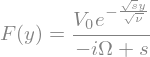

In [67]:
# F(y) stands for L{v_x}(y,s)
F = sp.Function('F')
ode = s*F(y) - nu*F(y).diff(y, 2)
# the general solution
display(sp.dsolve(ode, F(y)))
# the solution that satisfies both boundary conditions
# the condition at infinity works only because s is declared positive=True
sp.dsolve(ode, F(y), ics={F(0): V0/(s - sp.I*Omega), F(sp.oo): 0})

Thus,
$$
    \mathcal{L}\{v_x\}(y,s) = V_0\frac{e^{-y\sqrt{s/\nu}}}{s - \mathrm{i}\Omega}.
$$

## Laplace inversion

To invert $\mathcal{L}\{v_x\}(y,s)$, we need two Laplace transforms involving $\mathrm{erfc}(z) = 1 - \mathrm{erf}(z)$, the [complementary error function](https://en.wikipedia.org/wiki/Error_function). They are Eqs. ([7.14.4](https://dlmf.nist.gov/7.14.E4)) and ([7.14.4_5](https://dlmf.nist.gov/7.14.E4_5)) of the _NIST Digital Library of Mathematical Functions_ [(Olver _et al._, 2026)](https://dlmf.nist.gov/7.14#i), which in our variables read
\begin{align*}
    \mathcal{L}\left\{e^{\mathrm{i}\Omega t}\,\mathrm{erfc}\left(\frac{y}{2\sqrt{\nu t}} + \sqrt{\mathrm{i}\Omega t}\right)\right\} &= \frac{e^{-y\sqrt{\mathrm{i}\Omega/\nu}}\,e^{-y\sqrt{s/\nu}}}{\sqrt{s}\left(\sqrt{s} + \sqrt{\mathrm{i}\Omega}\right)},\\
    \mathcal{L}\left\{e^{\mathrm{i}\Omega t}\,\mathrm{erfc}\left(\frac{y}{2\sqrt{\nu t}} - \sqrt{\mathrm{i}\Omega t}\right)\right\} &= \frac{e^{y\sqrt{\mathrm{i}\Omega/\nu}}\,e^{-y\sqrt{s/\nu}}}{\sqrt{s}\left(\sqrt{s} - \sqrt{\mathrm{i}\Omega}\right)}.
\end{align*}

Multiply the first by $e^{y\sqrt{\mathrm{i}\Omega/\nu}}$ and the second by $e^{-y\sqrt{\mathrm{i}\Omega/\nu}}$, and add them. Since
$$
    \frac{1}{\sqrt{s}\left(\sqrt{s} + \sqrt{\mathrm{i}\Omega}\right)} + \frac{1}{\sqrt{s}\left(\sqrt{s} - \sqrt{\mathrm{i}\Omega}\right)} = \frac{2}{s - \mathrm{i}\Omega},
$$
the right-hand side is $2e^{-y\sqrt{s/\nu}}/(s - \mathrm{i}\Omega)$, and we can read off the inverse transform:
\begin{align*}
    v_x(y,t) = \frac{V_0}{2}H(t)\,e^{\mathrm{i}\Omega t}\bigg[ & e^{-y\sqrt{\mathrm{i}\Omega/\nu}}\,\mathrm{erfc}\left(\frac{y}{2\sqrt{\nu t}} - \sqrt{\mathrm{i}\Omega t}\right) \\
    &+ e^{y\sqrt{\mathrm{i}\Omega/\nu}}\,\mathrm{erfc}\left(\frac{y}{2\sqrt{\nu t}} + \sqrt{\mathrm{i}\Omega t}\right)\bigg].
\end{align*}
The $H(t)$ in front is the one from the boundary condition at the plate: its motion is switched on at $t=0$.

The DLMF states these two transforms for $|\mathrm{ph}\,a|<\pi/2$, where its $a$ is our $\mathrm{i}\Omega$, which sits on the edge of that range. This is one reason to check the final answer below.

Setting $\Omega=0$, we immediately recover $v_x(y,t) = V_0 H(t)\,\mathrm{erfc}\big(y/(2\sqrt{\nu t})\big)$, the solution of [Stokes' 1st problem](../Stokes_1st_problem.ipynb), where it is written as $1 - \mathrm{erf}$. SymPy can check that transform:

In [68]:
transform = sp.laplace_transform(sp.erfc(y/(2*sp.sqrt(nu*t))), t, s, noconds=True)
display(Math(r'\mathcal{L}\left\{\mathrm{erfc}\left(\frac{y}{2\sqrt{\nu t}}\right)\right\} = '
             + sp.latex(sp.simplify(transform.rewrite(sp.exp)))))

<IPython.core.display.Math object>

SymPy cannot invert $\mathcal{L}\{v_x\}(y,s)$ itself, so let's check the solution by substituting it back into the PDE. For $t>0$, $H(t)=1$.

In [69]:
# the complex solution, for t > 0
eta = y/(2*sp.sqrt(nu*t))
vx = V0/2*sp.exp(sp.I*Omega*t)*(sp.exp(-y*sp.sqrt(sp.I*Omega/nu))*sp.erfc(eta - sp.sqrt(sp.I*Omega*t))
                                + sp.exp(y*sp.sqrt(sp.I*Omega/nu))*sp.erfc(eta + sp.sqrt(sp.I*Omega*t)))

In [70]:
# does it satisfy the PDE?
display(Math(r'\frac{\partial v_x}{\partial t} - \nu\frac{\partial^2 v_x}{\partial y^2} = '
             + sp.latex(sp.simplify(vx.diff(t) - nu*vx.diff(y, 2)))))

<IPython.core.display.Math object>

In [71]:
# does it satisfy the boundary condition at the plate?
display(Math(r'v_x(0,t) = ' + sp.latex(sp.simplify(vx.subs(y, 0)))))

<IPython.core.display.Math object>

In [72]:
# does it satisfy the initial condition?
display(Math(r'\lim_{t\to0^+} v_x(y,t) = ' + sp.latex(sp.limit(vx, t, 0, '+'))))

<IPython.core.display.Math object>

Now let's use the same dimensionless variables as in Stokes' 2nd problem:
$$
    v_x^* = v_x/V_0,\quad y^* = y/\sqrt{2\nu/\Omega},\quad t^* = \Omega t.
$$
Since $\sqrt{\mathrm{i}} = (1+\mathrm{i})/\sqrt{2}$, we have $y\sqrt{\mathrm{i}\Omega/\nu} = (1+\mathrm{i})y^*$ and $\sqrt{\mathrm{i}\Omega t} = (1+\mathrm{i})\sqrt{t^*/2}$. The similarity variable of Stokes' 1st problem becomes $\eta = y/(2\sqrt{\nu t}) = y^*/\sqrt{2t^*}$. Taking the imaginary part, the solution is
\begin{align*}
    v_x^*(y^*,t^*) = H(t^*)\,\Im\bigg\{\frac{1}{2}e^{\mathrm{i}t^*}\Big[ &e^{-(1+\mathrm{i})y^*}\,\mathrm{erfc}\left(\eta - (1+\mathrm{i})\sqrt{t^*/2}\right) \\
    & + e^{(1+\mathrm{i})y^*}\,\mathrm{erfc}\left(\eta + (1+\mathrm{i})\sqrt{t^*/2}\right)\Big]\bigg\}.
\end{align*}

## Post-transient and transient parts

For large $t^*$, the argument of the first $\mathrm{erfc}$ heads off to infinity in the direction of $-(1+\mathrm{i})$, where $\mathrm{erfc}\to 2$. To see what this leaves behind, use $\mathrm{erfc}(-z) = 2 - \mathrm{erfc}(z)$ on the first term:
$$
    \frac{1}{2}e^{-(1+\mathrm{i})y^*}\,\mathrm{erfc}\left(\eta - (1+\mathrm{i})\sqrt{t^*/2}\right) = e^{-(1+\mathrm{i})y^*} - \frac{1}{2}e^{-(1+\mathrm{i})y^*}\,\mathrm{erfc}\left((1+\mathrm{i})\sqrt{t^*/2} - \eta\right).
$$
The first piece gives $\Im\left\{e^{\mathrm{i}t^*}e^{-(1+\mathrm{i})y^*}\right\} = e^{-y^*}\sin(t^* - y^*)$, which is the post-transient solution of Stokes' 2nd problem. So, for $t^*>0$,
$$
    v_x^*(y^*,t^*) = \underbrace{e^{-y^*}\sin(t^* - y^*)}_{\text{post-transient}} + \underbrace{\hat{v}_x^*(y^*,t^*)}_{\text{transient}},
$$
where
\begin{align*}
    \hat{v}_x^*(y^*,t^*) = -\Im\bigg\{\frac{1}{2}e^{\mathrm{i}t^*}\Big[ &e^{-(1+\mathrm{i})y^*}\,\mathrm{erfc}\left((1+\mathrm{i})\sqrt{t^*/2} - \eta\right) \\
    &- e^{(1+\mathrm{i})y^*}\,\mathrm{erfc}\left((1+\mathrm{i})\sqrt{t^*/2} + \eta\right)\Big]\bigg\}.
\end{align*}

This is Eq. (13) of Panton (1968) and Eq. (11.6.8) of Panton (2013), in our variables. Panton's $Y$ is our $\sqrt{2}\,y^*$, and he writes the complex conjugate of the expression in braces, with $C = 1 - \mathrm{i}$, which turns our $-\Im$ into his $\Im$.

The hat term denotes the difference between the full solution and the long-time solution. Both $\mathrm{erfc}$ terms in $\hat{v}_x^*$ go to $0$ as $t^*\to\infty$, so the transient dies out. As $t^*\to 0^+$, on the other hand, $\eta\to\infty$ and $\hat{v}_x^*\to e^{-y^*}\sin y^*$, which cancels the post-transient solution at $t^*=0$, so the fluid starts from rest.

SciPy's [`erfc`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.erfc.html) accepts complex arguments, so we can evaluate both parts directly. (Panton (1968) notes that $\mathrm{erfc}$ of a complex argument does not split into real and imaginary parts that are elementary functions. We don't need it to.)

In [73]:
def vx_post_transient(y, t):
    # the post-transient solution of Stokes' 2nd problem
    return np.exp(-y)*np.sin(t - y)


def vx_transient(y, t):
    # the transient part, valid for t > 0
    eta = y/np.sqrt(2*t)
    sqrt_it = (1 + 1j)*np.sqrt(t/2)  # this is sqrt(i*t)
    term1 = np.exp(-(1 + 1j)*y)*erfc(sqrt_it - eta)
    term2 = np.exp((1 + 1j)*y)*erfc(sqrt_it + eta)
    return -np.imag(0.5*np.exp(1j*t)*(term1 - term2))


def vx_startup(y, t):
    # the full start-up solution, valid for t > 0
    return vx_post_transient(y, t) + vx_transient(y, t)

# VISUALIZATION

## The first cycle

Let's look at the start-up solution at eight instants during the _first_ cycle of the plate's motion.

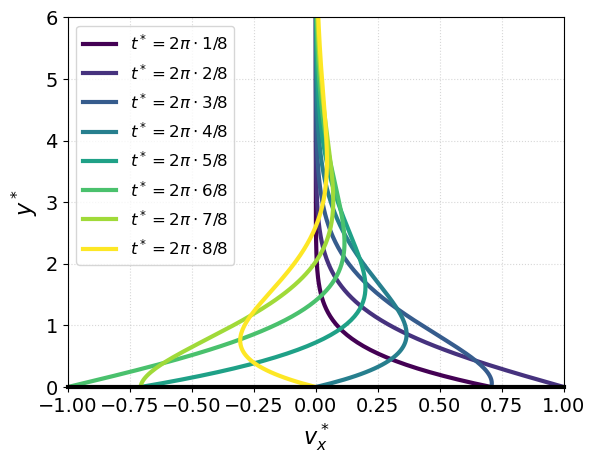

In [74]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, 200)

# sequential colormap with gradient that looks nice, dark (early) to bright (late)
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)

ax.grid(alpha=0.5, linestyle='dotted')

for k in range(1, 9):
    tstar = 2*np.pi*k/8
    vx = vx_startup(y, tstar)
    ax.plot(vx, y,
            linewidth=3, color=cmap((k - 1)/7), label=rf'$t^* = 2\pi\cdot{k}/8$')

# the plate
ax.plot([-1, 1], [0, 0], linewidth=3, color='black', clip_on=False)

ax.legend(loc='upper left');

During the first half cycle, the fluid near the plate is simply dragged along with it, much as in Stokes' 1st problem. The decaying, oscillating shape of the post-transient solution builds up over the first cycle.

To see how far the start-up solution is from the post-transient one, let's plot them together (solid and dashed, respectively) at five of these instants, as in Fig. 11.6 of Panton (2013).

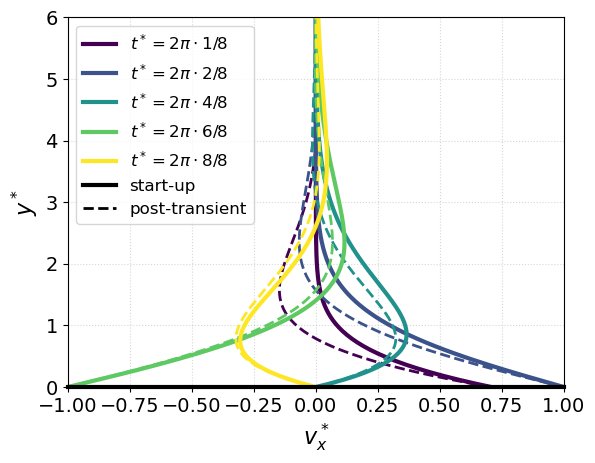

In [75]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, 200)

# sequential colormap with gradient that looks nice, dark (early) to bright (late)
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)

ax.grid(alpha=0.5, linestyle='dotted')

# five instants during the first cycle, t* = 2*pi*k/8
ks = [1, 2, 4, 6, 8]
for i in range(len(ks)):
    tstar = 2*np.pi*ks[i]/8
    tcol = cmap(i/(len(ks) - 1))  # argument from 0 to 1
    ax.plot(vx_startup(y, tstar), y,
            linewidth=3, color=tcol, label=rf'$t^* = 2\pi\cdot{ks[i]}/8$')
    ax.plot(vx_post_transient(y, tstar), y,
            linewidth=2, linestyle='dashed', color=tcol)

# legend entries for the two line styles
ax.plot([], [], linewidth=3, color='black', label='start-up')
ax.plot([], [], linewidth=2, linestyle='dashed', color='black', label='post-transient')

# the plate
ax.plot([-1, 1], [0, 0], linewidth=3, color='black', clip_on=False)

ax.legend(loc='upper left');

Early on, the two are far apart. At $t^* = 2\pi\cdot 1/8$, the fluid near the plate is dragged along with it, while the post-transient solution already has fluid moving backward farther out. The gap closes over the first cycle, and by $t^* = 2\pi$ the two profiles nearly coincide.

## Animation

Next, let's animate the start-up solution together with the post-transient solution (dashed) over the first three cycles.

In [76]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, endpoint=True)

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)
# if you want to move horizontal axis label to top so it doesn't clash with animation controls
# but fig.tight_layout() below also fixes this
# ax.xaxis.set_label_position('top')
# ax.xaxis.set_ticks_position('top')
plt.close()

# initialize plot and quiver objects with some dummy data (replaced in animation)
line, = ax.plot(0*y, y,
                linewidth=4, color='darkblue', label='start-up solution,\n' + r'$t^* = 2\pi\cdot 0.000$')
line_post, = ax.plot(0*y, y,
                     linewidth=2, linestyle='dashed', color='#D55E00', label='post-transient\nsolution')
# add envelope of the post-transient curves
ax.plot(np.exp(-y), y,
        linewidth=2, linestyle='dotted', color='gray', label='envelope, $e^{-y^*}$')
ax.plot(-np.exp(-y), y,
        linewidth=2, linestyle='dotted', color='gray')
# skip every other data point to reduce number of arrows
quiv = ax.quiver(0*y[::2], y[::2], 0*y[::2], 0*y[::2],
                 scale=1., scale_units='xy', color='blue', zorder=2)
# the plate
ax.plot([-1, 1], [0, 0], linewidth=3, color='black', clip_on=False)
ax.legend(loc='upper right')

# number of animation frames
numframes = 120
tmax = 6*np.pi

# animation function called sequentially by `FuncAnimation' below
def animate(i):
    # the i passed is the frame counter, not time, so rescale it to get t^*
    # also shift it by one frame, so we don't divide by 0 at t^* = 0
    tstar = (i + 1)/numframes * tmax

    vx = vx_startup(y, tstar)
    line.set_data(vx, y)
    # update the label, in multiples of 2*pi with 3 decimals, and redraw the legend
    line.set_label('start-up solution,\n' + rf'$t^* = 2\pi\cdot{tstar/(2*np.pi):.3f}$')
    # plot arrows emanating only from the reference line, x-coord = 0
    quiv.set_UVC(vx[::2], 0*vx[::2])
    line_post.set_data(vx_post_transient(y, tstar), y)

    ax.legend(loc='upper right')
    ax.grid(alpha=0.5, linestyle='dotted')

    return (line, line_post, quiv,)

# lay out the figure once, so the axes don't shift by a pixel between frames
fig.tight_layout()

anim = animation.FuncAnimation(fig, animate,
                               frames=numframes, interval=100, blit=True)

In [77]:
# this is necessary to get the animation to work on Google's Colab
rc('animation', html='jshtml')
anim

In [78]:
# To save the animation, use something like
# anim.save(f"Stokes_2nd_prob_transient_movie.mp4")

# or
# writer = animation.FFMpegWriter(fps=15, metadata=dict(artist='Me'), bitrate=1800)
# anim.save(f"Stokes_2nd_prob_transient_movie.mp4", writer=writer)

At first, the post-transient solution has fluid moving (even backward) far from the plate, where the start-up solution has not yet set the fluid in motion. Within the first cycle, the two solutions become close, and by the end of the third cycle they are hard to tell apart at the scale of the plot.

## How long does the transient last?

To see how quickly the start-up solution approaches the post-transient one, let's compute the largest value of $|\hat{v}_x^*|$ across the fluid as a function of time. The transient spreads away from the plate, so we need a tall grid in $y^*$.

In [79]:
y = np.linspace(0, 60, 3001)
tstars = np.logspace(-1, 2.5, 200)

max_transient = np.zeros_like(tstars)
for i in range(len(tstars)):
    max_transient[i] = np.max(np.abs(vx_transient(y, tstars[i])))

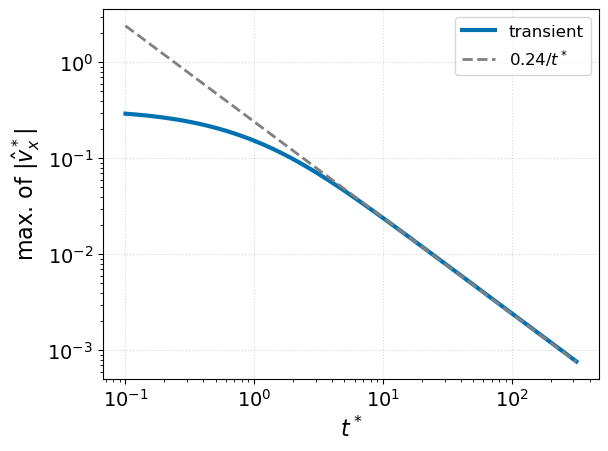

In [80]:
fig, ax = plt.subplots()
ax.set_xlabel('$t^*$')
ax.set_ylabel(r'max. of $|\hat{v}_x^*|$')
ax.set_xscale('log')
ax.set_yscale('log')

ax.grid(alpha=0.5, linestyle='dotted')

ax.plot(tstars, max_transient,
        linewidth=3, color='#0072B2', label='transient')
ax.plot(tstars, 0.24/tstars,
        linewidth=2, linestyle='dashed', color='gray', label='$0.24/t^*$')

ax.legend();

For $t^*$ larger than about 10, the curve follows the dashed line, $0.24/t^*$: the transient decays like $1/t^*$. After one cycle ($t^*=2\pi$), it is still about 4% of the plate's velocity amplitude, $V_0$.

When does it drop below 1% of $V_0$? Let's find out using [SciPy](https://docs.scipy.org/doc/scipy/reference/optimize.html#root-finding)'s nonlinear root-finding capabilities.

In [84]:
def eq_func(tstar):
    # define a function max|transient|(t*) - 0.01, which = 0 for the value
    # of t* that we seek as a solution
    return np.max(np.abs(vx_transient(y, tstar))) - 0.01

# eq_func changes sign between t* = 10 and t* = 50, so bracket the root there
sol = root_scalar(eq_func, bracket=[10, 50])
tstar_sol = sol.root
display(Math(rf't^*_{{1\%}} \approx {tstar_sol:.2f} \approx 2\pi\cdot{tstar_sol/(2*np.pi):.2f}'))

<IPython.core.display.Math object>

So it takes almost four cycles, for the transient to drop below 1% of $V_0$. Judging by the velocity profiles, Panton (1968) concluded that the transient is essentially complete after one cycle. The profiles are indeed close after one cycle, as the animation shows, but the last few percent die out slowly.

Compare with the startup PC flow, for which the transient decays like $e^{-\pi^2 t^*}$, and the channel's width sets the slowest-decaying mode. Here, the fluid is unbounded, so there is no slowest mode. Instead, the transient keeps spreading away from the plate while it decays, and it decays algebraically, not exponentially.

A clarification: Panton (1968) wrote that the transient dies out rapidly because of the factor $e^{-\nu\zeta^2 t}$ in an integral form of the solution, where $\zeta$ is a wavenumber. Each wavenumber does decay exponentially, but the integral includes wavenumbers down to $\zeta=0$, which decay ever more slowly, and together they give the algebraic decay.

# FURTHER EXPLORATION

On your own:
*   Compute the shear stress on the plate during start-up, and compare it with the post-transient one. How long does it take for the two to agree to within 1%?
*   Start the plate as $V_0 H(t)\cos(\Omega t)$ instead, and take the real part, $\Re$, at the end. Now the plate velocity jumps at $t=0$: compare the solution at early times with Stokes' 1st problem. How long does this transient last?
*   For large $t^*$, show that $t^*\hat{v}_x^*$ becomes a function of $\eta$ alone, and use it to explain the $0.24/t^*$ line in the last figure.
*   Panton (2013) mentions Duhamel's integral at the end of Section 11.6. Use the convolution theorem for the Laplace transform to write the start-up solution as a superposition of solutions of Stokes' 1st problem, and check it numerically against the formula above.
*   Explore the start-up problem for a viscoelastic fluid. For an Oldroyd-B fluid, [Christov (2015)](https://arxiv.org/abs/1506.01470) gives the solution in the Laplace domain, as we did above for a Newtonian fluid. Does the fluid's elasticity make the transient last longer?
    - The solution is inverted and verified, and its early- and late-time asymptotics are worked out, in [christov_2015_oldroydb_stokes2](https://github.com/ichristov/viscoelastic-startup/blob/main/notebooks/christov_2015_oldroydb_stokes2.ipynb), part of the viscoelastic-startup repository [(Christov, 2026)](https://github.com/ichristov/viscoelastic-startup). Long after the start, the transient at a fixed distance from the plate decays as it would for a Newtonian fluid, whatever the fluid's relaxation and retardation times.
    - For a plate started as $V_0 H(t)\cos(\Omega t)$, the velocity jumps at $t=0$. Dropping this jump led to wrong published solutions for many classes of viscoelastic fluids; see also [Christov & Jordan (2012)](https://arxiv.org/abs/1111.4464) and [christov_jordan_2012_second_grade_stokes2](https://github.com/ichristov/viscoelastic-startup/blob/main/notebooks/christov_jordan_2012_second_grade_stokes2.ipynb).

# REFERENCES

I. C. Christov, P. M. Jordan, Comments on: "Starting solutions for some unsteady unidirectional flows of a second grade fluid" [Int. J. Eng. Sci. 43 (2005) 781], _Int. J. Eng. Sci._ **51** (2012) 326&ndash;332. [doi:10.1016/j.ijengsci.2011.10.012](https://doi.org/10.1016/j.ijengsci.2011.10.012); [arXiv:1111.4464](https://arxiv.org/abs/1111.4464)

I. C. Christov, On a difficulty in the formulation of initial and boundary conditions for eigenfunction expansion solutions for the start-up of fluid flow, _Mech. Res. Commun._ **51** (2013) 86&ndash;92. [doi:10.1016/j.mechrescom.2013.05.005](https://doi.org/10.1016/j.mechrescom.2013.05.005); [arXiv:1305.5999](https://arxiv.org/abs/1305.5999)

I. C. Christov, Comment on "The velocity field due to an oscillating plate in an Oldroyd-B fluid" by C.C. Hopkins and J.R. de Bruyn [Can. J. Phys. 92, 533 (2014)], _Can. J. Phys._ **93** (2015) 1651&ndash;1652. [doi:10.1139/cjp-2015-0374](https://doi.org/10.1139/cjp-2015-0374); [arXiv:1506.01470](https://arxiv.org/abs/1506.01470)

I. C. Christov, viscoelastic-startup: Verification and reproducibility of exact solutions for start-up flows of viscoelastic fluids (Jupyter notebooks), Zenodo, 2026. [doi:10.5281/zenodo.22930189](https://doi.org/10.5281/zenodo.22930189); [<img src="https://github.githubassets.com/images/icons/emoji/octocat.png" width="20" alt="Octocat"> GitHub](https://github.com/ichristov/viscoelastic-startup)

F. W. J. Olver, A. B. Olde Daalhuis, D. W. Lozier, B. I. Schneider, R. F. Boisvert, C. W. Clark, B. R. Miller, B. V. Saunders, H. S. Cohl, M. A. McClain (Eds.), _NIST Digital Library of Mathematical Functions_, Release 1.2.8, National Institute of Standards and Technology, 2026. [Full text](https://dlmf.nist.gov/)

R. L. Panton, The transient for Stokes's oscillating plate: a solution in terms of tabulated functions, _J. Fluid Mech._ **31** (1968) 819&ndash;825. [doi:10.1017/s0022112068000509](https://doi.org/10.1017/s0022112068000509)

R. L. Panton, _Incompressible Flow_, 4th ed., Wiley, 2013. [doi:10.1002/9781118713075](https://doi.org/10.1002/9781118713075)

G. G. Stokes, On the effect of the internal friction of fluids on the motion of pendulums, _Trans. Camb. Philos. Soc._ **9** (Part II) (1850); reprint, Pitt Press, Cambridge, 1851, pp. 1&ndash;99. [Full text](https://archive.org/details/b22464074/page/92/mode/2up)